# Máquinas de Boosting Explicáveis

### Alunas: Maria Emily Nayla Gomes da Silva (24019) e Rafaela Beatriz Silva Luz (24021)

Neste notebook, será explorada a aplicação do algoritmo de predição de **Máquinas de Boosting Explicáveis (EBM, do inglês *Explainable Boosting Machines*)** da classe dos **modelos lineares generalizados (GLM, do inglês *Generalized Additive Model*)** [1]. Este modelo de Inteligência Artificial (IA) em estado da arte se destaca pela **alta explicabilidade** da importância dos atributos em relação à previsão do alvo associada a um **excelente desempenho** após treinamentos bem-sucedidos, como mostrado na figura abaixo [2]. 

![img](https://archive.ph/QbEVk/4d50a01941fd20d82ae58661aefcc0c129ffc6f9.webp)

Nesse sentido, a aplicação do EBM será feita com o módulo `interpret` [3].
> **Objetivo:** integrar **modelagem preditiva** e **interpretabilidade**, utilizando os dados não apenas para classificar moléculas quanto à retenção em Gram-negativas, mas também como suporte à busca de relações entre esse alvo funcional  e as propriedades moleculares e a retenção em bactérias Gram-negativas.

## Importações, variáveis gerais e funções de apoio

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from interpret import show
from interpret.glassbox import ExplainableBoostingClassifier

from sklearn.base import clone
from sklearn.feature_selection import VarianceThreshold
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegressionCV
from sklearn.calibration import CalibratedClassifierCV
from sklearn.utils.class_weight import compute_sample_weight
from interpret.glassbox import ExplainableBoostingClassifier
from sklearn.metrics import (
    accuracy_score, recall_score, precision_score, f1_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss, 
    confusion_matrix, ConfusionMatrixDisplay
)

In [2]:
SEMENTE_ALEATORIA = 200404
COLUNA_SMILES = "SMILES"
DATASET_MODELO = "all_df_model_descriptors.csv" 
NUM_FOLDS = 5

cols_id = [COLUNA_SMILES, "Clean SMILES"]
cols_nao_atributos = cols_id + ["Retention"] + ["Split"]

df = pd.read_csv(DATASET_MODELO)

FEATURES = [col for col in df.columns if col not in cols_nao_atributos]
TARGET = ["Retention"]

## Dataset de treino
 
O dataset utilizado neste trabalho contém **179 descritores físico-químicos** de várias pequenas moléculas, além da identificação das amostras destinadas aos conjuntos de **treino e teste**. A variável-alvo (o *target*) é a coluna **`Retention`**, em que:
 
- **0** → não retenção da molécula em bactérias Gram-negativas;
- **1** → retenção da molécula em bactérias Gram-negativas.
 
Neste notebook, serão avaliadas diferentes **técnicas de aprendizado de máquina**, combinando abordagens empregadas no artigo de referência [4], que disponibilizou as estruturas moleculares no formato **SMILES** e suas respectivas informações de retenção, com esforços voltados à melhoria do desempenho preditivo. Dado que o uso da plataforma de *low-coding* informada na fonte se demonstrou desafiador para as estudantes e que o modelo será aplicado sobre uma biblioteca com os *SMILES* de compostos *lead-like* para sua monografia, houve um **empenho preliminar na formação do *dataset*** aqui utilizado (`"all_df_model_descriptors.csv"`) no sentido de captura de descritores moleculares a partir do módulo **RDKit** [5]. As **6406 amostras** também já foram particionados na seguinte proporção: **90% de dados de treino e 10% de dados de teste**.
 
Será dada atenção especial à **sensibilidade (*recall*) para a classe de moléculas retidas**, uma vez que a identificação desses compostos no rótulo correto é particularmente relevante para evitar a perda de potenciais *hits* para a classe negativa.

In [3]:
df_treino = df[df["Split"] == "Train"]
df_teste = df[df["Split"] == "Test"]

X_treino_raw = df_treino.reindex(FEATURES, axis=1).values
y_treino = df_treino[TARGET].values.ravel()

X_teste_raw = df_teste.reindex(FEATURES, axis=1).values
y_teste = df_teste[TARGET].values.ravel()

## Seleção de atributos

Foi adotada uma seleção sequencial de atributos no conjunto de dados de entrada. Assim, foi feita a **remoção de atributos pouco informativos**, viabilizando o treinamento de um modelo preditivo eficiente para a identificação de moléculas **sem sacrificar o desempenho das métricas**. Para isso, a referência inicial consistiu nas ***features* de treino** carregadas, evitando o vazamento de dados e também considerando que a relevância desses dados será aquela considerada ao longo da proposição do modelo.

### Retirada de colunas com variância nula

A aplicação desse método garante a identificação e **eliminação imediata de colunas de valor único**.

In [4]:
seletor_var = VarianceThreshold(threshold=0.0)
X_treino_var = seletor_var.fit_transform(X_treino_raw)
X_teste_var = seletor_var.transform(X_teste_raw)

nomes_apos_var = np.array(FEATURES)[seletor_var.get_support()].tolist()

### Pré-seleção baseada em conhecimento químico e biológico

São de especial importância os atributos que foi possível computar entre aqueles correspondentes aos **aplicados no artigo de referência [4]** dada a *expertise* relacionada à escolha realizada pelos autores. Concomitantemente, foi carreada uma análise prévia de dados a partir da qual foram feitas algumas substituições dessas características, conforme detalhado abaixo.

Para a procura de átomos simétricos, todos foram ranqueados de maneira canônica e sem desempate dos equivalentes químicos; posteriormente, foi aferida a diferença entre o número total de átomos e a contagem do ranqueamento. O índice topológico de flexibilidade de Hall-Kier [6] foi adotado como índice de forma. Além disso, o número ciclomático em grafos planares e árvores define a quantidade fundamental de fechamentos de ciclo no esqueleto molecular, esse direcionamento foi seguido para um cálculo a partir da relação de Euler [7].

Ainda que as variáveis explicadas neste parágrafo correspondessem a uma mesma propriedade da molécula, considerou-se importante manter ambas dado que, para cada caso, uma era a contagem discreta e a outra era normalizada pelo tamanho da molécula, uma vez que se trata de uma relação não linear que pode não ser um padrão trivial para captura pela EBM, por exemplo. Além da estimativa da área total da superfície polar (TPSA, do inglês Topological Polar Surface Area), foi considerada a fração da superfície polar pela divisão entre TPSA e a área de Van der Waals completa da molécula. Mesmo considerando que a quantidade de ligações rotacionáveis já havia sido um critério utilizado para a pré-filtragem (≤ 5) do dataset de *hits* na aplicação das duas últimas (inclusive a regra de globularidade ≤ 0,25 para limitação de tridimensionalidade) regras do conjunto eNTRy [8] para entrada em gram-negativas, foi mantida essa contagem e a fração de flexibilidade molecular (número de ligações rotacionáveis / número de átomos pesados). 

Além da contagem de anéis pequenos, considerados com até 4 átomos, foram contados os macrociclos, considerados importantes unidades químicas relacionadas à atividade antibacteriana de compostos naturais e à biodisponibilidade intracelular [9]. Também foram contados os átomos do tipo *spiro*, aqueles compartilhados entre ciclos adjacentes unidos apenas por esse átomo, e associados à flexibilidade e às conformações de moléculas policíclicas, dados os padrões específicos de seletividade e potência em candidatos a fármacos que os apresentam [10]. Também foram acrescidos descritores de cargas formais, incluindo a soma algébrica das cargas formais, a soma de seus valores absolutos e a contagem de átomos com tais cargas positivas e negativas.

Ademais, algumas características citadas no artigo não foram avaliadas dada sua redundância (heteroátomos com átomos não C ou H e eletronegativos) ou ausência de variação (átomos metálicos) no conjunto de dados. A detecção de nitrogênios básicos foi omitida em favor da detecção de fragmentos padrão identificáveis pelo RDKit, que inclui aminas (primárias, secundárias e terciárias) e piridinas (nitrogênios aromáticos sem H conectado). Por sua vez, a detecção de nitrogênios aromáticos também foi decomposta na detecção de piridinas e pirróis vinculados a H. Similarmente, o encontro de oxigênios ácidos foi possível graças aos fragmentos de ácidos carboxílicos (subdivididos entre alifáticos e aromáticos) e fenóis. Da mesma forma, aminas aromáticas foram localizadas pela presença de anilinas e nitrogênios pirrólicos hidrogenados. Também foi feita a contabilização de amidas, enquanto a de aminas foi tomada pelos componentes dessa classe supracitados.

De mais a mais, a contagem de heteroátomos, de átomos pesados e de carbonos foi substituída por uma contagem por elemento para cada elemento permitido após a sanitização. Também não foi feita a contagem de átomos não hidrogênio, que também se relacionaria linearmente com essa proposta apresentada. 

In [5]:
atributos_pre_selecionados = [
    # Propriedades físico-químicas
    "cLogP",
    "Topological Polar Surface Area",
    "Polar Surface Fraction",
    "Molecular Weight",
    "Molecular Complexity",
    "Molecular Flexibility",
    "Rotatable Bonds",
    "Shape Index",

    # Átomos e composição molecular
    "Fraction C sp3",
    "Symmetric atoms",
    "Aromatic Atoms",
    "Carbon sp3 Atoms",
    "Carbon Count",
    "Nitrogen Count",
    "Oxygen Count",
    "Fluorine Count",
    "Phosphorus Count",
    "Sulfur Count",
    "Chlorine Count",
    "Bromine Count",
    "Iodine Count",

    # Estereoquímica e propriedades de interação
    "Stereo Centers",
    "H-Donors",
    "H-Acceptors",

    # Anéis e topologia
    "Aromatic Rings",
    "Aliphatic Rings",
    "Saturated Rings",
    "Aromatic Carbocycles",
    "Saturated Carbocycles",
    "Aliphatic Carbocycles",
    "Aromatic Heterocycles",
    "Saturated Heterocycles",
    "Aliphatic Heterocycles",
    "Small Rings",
    "Rings Closures",

    # Atributos adicionais de anéis
    "Macrocycles",
    "Spiro Atoms",

    # Aminas e nitrogênios
    "Primary Amines",
    "Secondary Amines",
    "Tertiary Amines",
    "Pyridine Rings",
    "H-Pyrrole Nitrogens",
    "Anilines",

    # Grupos funcionais relacionados à acidez
    "Aliphatic Carboxylic Acids",
    "Aromatic Carboxylic Acids",
    "Phenols",

    # Amidas
    "Amides",
    
    # Cargas
    "Formal Charge",
    "Positive Charge Atoms",
    "Negative Charge Atoms",
    "Absolute Formal Charge",
]

### Seleção com regressão logística LASSO

A **regularização LASSO** (*Least Absolute Shrinkage and Selection Operator*, operador de seleção e encolhimento mínimo absoluto) promove a seleção de atributos por meio da **penalização L1**, favorecendo soluções nas quais **coeficientes de atributos correlacionados são reduzidos a zero** [11]. Durante sua aplicação aos atributos pré-selecionados, utilizou-se a **função de pontuação ROC-AUC** (*Receiver Operating Characteristic – Area Under the Curve*, área sob a curva característica de operação do receptor), que quantifica a capacidade discriminativa do modelo ao considerar diferentes limiares de classificação, sem exigir a definição prévia de um limiar específico. Para a consideração das classes com semelhante importância, o modelo LASSO foi aplicado com balanceamento de classes. Cumpre ressaltar que a lista de atributos de saída desta célula foi utilizada também para o modelo explicável entregue no outro *notebook* deste trabalho.

In [6]:
# Manter somente atributos pré-selecionados não constantes, com a ordem de entrada
atributos_pre_disponiveis = [feat for feat in atributos_pre_selecionados if feat in nomes_apos_var]

atributos_ausentes = [feat for feat in atributos_pre_selecionados if feat not in nomes_apos_var]

print(f"Atributos pré-selecionados: {len(atributos_pre_selecionados)}")
print(f"Atributos pré-selecionados disponíveis: {len(atributos_pre_disponiveis)}")
print(f"Atributos ausentes ou constantes entre os pré-selecionados: {len(atributos_ausentes)}")

if atributos_ausentes:
    print("\nAtributos não utilizados:")
    print(atributos_ausentes)

# Extrair as colunas na mesma ordem dos nomes
indices_pre = [nomes_apos_var.index(feat) for feat in atributos_pre_disponiveis]

X_treino_pre = X_treino_var[:, indices_pre]
X_teste_pre = X_teste_var[:, indices_pre]

# Validação cruzada estratificada para escolher a regularização
cv_selecao = StratifiedKFold(n_splits=NUM_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA)

seletor = make_pipeline(
    StandardScaler(),
    LogisticRegressionCV(
        Cs=10,
        cv=cv_selecao,
        l1_ratios=(1.0,),
        solver="saga",
        scoring="roc_auc", 
        class_weight="balanced",
        max_iter=10000,
        random_state=SEMENTE_ALEATORIA,
        n_jobs=-1,
        use_legacy_attributes=False
    )
)

# Ajustar a seleção usando exclusivamente o conjunto de treino
seletor.fit(X_treino_pre, y_treino)

modelo_logistico = seletor.named_steps["logisticregressioncv"]
coeficientes = modelo_logistico.coef_.ravel()
print(f"\nMelhor C escolhido pelo LASSO (LogisticRegressionCV): {modelo_logistico.C_:.4f}")

# Selecionar atributos com coeficientes diferentes de zero
mascara_selecao = np.abs(coeficientes) > 1e-8

# Salva os atributos selecionados correspondendo à ordem na lista de pré-selecionados variáveis 
atributos_selecionados = np.array(atributos_pre_disponiveis)[mascara_selecao].tolist()

print(f"Atributos selecionados pelo LASSO: {len(atributos_selecionados)}")
print(f"Atributos descartados pelo LASSO: {len(atributos_pre_disponiveis) - len(atributos_selecionados)}")

print("\nAtributos selecionados:")
for atributo in atributos_selecionados:
    print(atributo)

# Matrizes finais de atributos selecionados
X_treino_sel = pd.DataFrame(X_treino_pre[:, mascara_selecao], columns=atributos_selecionados)

X_teste_sel = pd.DataFrame(X_teste_pre[:, mascara_selecao], columns=atributos_selecionados)

Atributos pré-selecionados: 51
Atributos pré-selecionados disponíveis: 51
Atributos ausentes ou constantes entre os pré-selecionados: 0

Melhor C escolhido pelo LASSO (LogisticRegressionCV): 2.7826
Atributos selecionados pelo LASSO: 43
Atributos descartados pelo LASSO: 8

Atributos selecionados:
cLogP
Topological Polar Surface Area
Polar Surface Fraction
Molecular Weight
Molecular Complexity
Molecular Flexibility
Rotatable Bonds
Shape Index
Fraction C sp3
Symmetric atoms
Aromatic Atoms
Carbon Count
Oxygen Count
Phosphorus Count
Sulfur Count
Chlorine Count
Bromine Count
Iodine Count
Stereo Centers
H-Donors
H-Acceptors
Aromatic Rings
Aliphatic Rings
Saturated Carbocycles
Aromatic Heterocycles
Saturated Heterocycles
Aliphatic Heterocycles
Small Rings
Rings Closures
Macrocycles
Spiro Atoms
Primary Amines
Secondary Amines
Tertiary Amines
Pyridine Rings
H-Pyrrole Nitrogens
Anilines
Aliphatic Carboxylic Acids
Aromatic Carboxylic Acids
Phenols
Amides
Formal Charge
Negative Charge Atoms


## Treinamento do modelo e métricas

Com um conjunto de dados refinado, chega o momento de aplicação do modelo EBM intrinsecamente interpretável, conforme mencionado no início desta tarefa. Foi adotado o balanceamento de classes de forma a evitar problemas de subrepresentação de moléculas com retenção positiva. 

Adicionalmente, foi implementada a calibração do modelo por meio da classe `CalibratedClassifierCV` [11]. Tal passo é essencial para garantir que as probabilidades previstas pelo método `predict_proba` se aproximem do nível de confiança (LoC, do inglês *Level of Confidence*) [1]. Isso assegura estimativas confiáveis para a ordenação de moléculas *hit-like* para a triagem virtual, viabilizando análises consistentes nas etapas posteriores da monografia.


Treinamento e calibração concluídos com sucesso.

===== RESULTADOS NO TESTE INDEPENDENTE =====
Recall / Sensibilidade: 75.00%
Especificidade:         78.21%
Precisão:               65.52%
Acurácia:               77.07%
F1-score:               69.94%
ROC-AUC:                83.29%


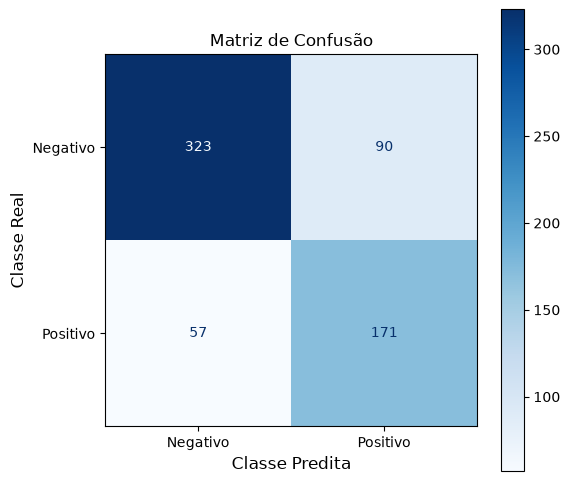

In [7]:
# Pesos balanceados para o conjunto de treino
pesos_treino = compute_sample_weight(class_weight="balanced", y=y_treino)

# Instanciar o EBM com os hiperparâmetros escolhidos
modelo_base = ExplainableBoostingClassifier(interactions=0, random_state=SEMENTE_ALEATORIA)

# Calibrar as probabilidades com validação cruzada, ensemble=False garante o treinamento de um único modelo
modelo_calibrado = CalibratedClassifierCV(estimator=modelo_base, method="sigmoid", cv=NUM_FOLDS, ensemble=False)

# Treinar o modelo balanceado e calibrado
modelo_calibrado.fit(X_treino_sel, y_treino, sample_weight=pesos_treino)

# Recuperar o EBM ajustado dentro do calibrador
ebm_ajustado = (modelo_calibrado.calibrated_classifiers_[0].estimator)

print("\nTreinamento e calibração concluídos com sucesso.")

# Avaliação final no conjunto de teste independente
y_prob_teste = modelo_calibrado.predict_proba(X_teste_sel)[:, 1]
y_pred_teste = (y_prob_teste >= 0.5).astype(int)

vn, fp, fn, vp = confusion_matrix(y_teste, y_pred_teste, labels=[0, 1]).ravel()

sensibilidade = recall_score(y_teste, y_pred_teste, zero_division=0)
precisao = precision_score(y_teste, y_pred_teste, zero_division=0)
acuracia = accuracy_score(y_teste, y_pred_teste)
f1_score = f1_score(y_teste, y_pred_teste, zero_division=0)
especificidade = vn / (vn + fp) if (vn + fp) > 0 else np.nan
roc_auc = roc_auc_score(y_teste, y_prob_teste)

print("\n===== RESULTADOS NO TESTE INDEPENDENTE =====")
print(f"Recall / Sensibilidade: {sensibilidade * 100:.2f}%")
print(f"Especificidade:         {especificidade * 100:.2f}%")
print(f"Precisão:               {precisao * 100:.2f}%")
print(f"Acurácia:               {acuracia * 100:.2f}%")
print(f"F1-score:               {f1_score * 100:.2f}%")
print(f"ROC-AUC:                {roc_auc * 100:.2f}%")

# Plotagem da matriz de confusão
cm = np.array([
    [vn, fp],
    [fn, vp]
])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negativo", "Positivo"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax)

ax.set_xlabel("Classe Predita", fontsize=12)
ax.set_ylabel("Classe Real", fontsize=12)

plt.title("Matriz de Confusão")

plt.savefig("matriz_nossomodelo.png", dpi=800, bbox_inches="tight")
plt.show()

Como referência, o modelo reportado no artigo de referência [4], a partir do qual foram obtidas as informações de **SMILES** e retenção molecular, apresentou uma matriz de confusão em moléculas externas ao treino na sua figura 6, a qual foi usada como *input* para conferência de todas suas métricas no código abaixo.

--- Resultados da matriz de confusão da referência ---
Recall / Sensibilidade: 77.83%
Especificidade:         74.77%
Precisão:               74.66%
Acurácia:               76.27%
F1-Score:               76.21%


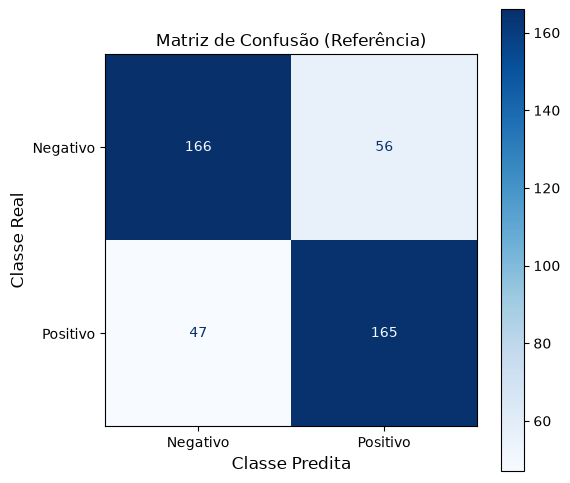

In [8]:
# Valores da matriz de confusão de referência
vp_ref = 165
fn_ref = 47
fp_ref = 56
vn_ref = 166

# Cálculo manual das métricas principais
total_ref = vp_ref + vn_ref + fp_ref + fn_ref
acuracia_ref = (vp_ref + vn_ref) / total_ref
sensibilidade_ref = vp_ref / (vp_ref + fn_ref)      
especificidade_ref = vn_ref / (vn_ref + fp_ref)     
precisao_ref = vp_ref / (vp_ref + fp_ref)       
f1_score_ref = 2 * (precisao_ref * sensibilidade_ref) / (precisao_ref + sensibilidade_ref)

# Impressão das métricas em porcentagem
print("--- Resultados da matriz de confusão da referência ---")
print(f"Recall / Sensibilidade: {sensibilidade_ref * 100:.2f}%")
print(f"Especificidade:         {especificidade_ref * 100:.2f}%")
print(f"Precisão:               {precisao_ref * 100:.2f}%")
print(f"Acurácia:               {acuracia_ref * 100:.2f}%")
print(f"F1-Score:               {f1_score_ref * 100:.2f}%")

# Plotagem da matriz de confusão
cm = np.array([
    [vn_ref, fp_ref],
    [fn_ref, vp_ref]
])

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negativo", "Positivo"])

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap="Blues", values_format="d", ax=ax)

ax.set_xlabel("Classe Predita", fontsize=12)
ax.set_ylabel("Classe Real", fontsize=12)

plt.title("Matriz de Confusão (Referência)")

plt.savefig("matriz_referencia.png", dpi=800, bbox_inches="tight")
plt.show()

### Discussão

As **métricas foram comparáveis com aquelas do artigo de referência** [4]. Especialmente, observa-se uma sensibilidade (75.00%) um pouco menor que a de referência (77.83%). Entretanto, a acurácia ficou um pouco melhor (77.07% em comparação com 76.27%). A precisão (65.52%) apresentou diferença de cerca de 10% quando comparada à da referência (74.66%), alertando para uma menor capacidade do modelo aqui treinado de alocar corretamente as moléculas na classe negativa. O *F1-score* (69.94%) também foi mais baixo que o do artigo (76.21%), demonstrando um desempenho menos favorável no equilíbrio entre precisão e sensibilidade.

Para o classificador aqui proposto, as métricas de área sob a curva também puderam ser aferidas. O ROC-AUC apresentou o maior valor entre todos os avaliados para o modelo (83.29%), o qual indica uma boa capacidade do modelo de ordenar moléculas positivas acima das negativas quanto à probabilidade da classe positiva para diferentes limiares de classificação. Essa métrica é importante para endossar a posterior escolha de moléculas mais promissoras quanto à retenção na biblioteca de compostos semelhantes a *leads*, uma vez que essas serão selecionadas pela predição de classe positiva obrigatória e ordenação pela maior probabilidade da predição positiva. Para esse prosseguimento das atividades, cumpre ressaltar também que será tomada uma pequena parcela do *dataset* original, dadas as limitações de quantidade de cálculos durante o período da monografia, o que ressalta a necessidade de que essas poucas moléculas com alta chance de retenção predita correspondam com essa característica na prática. 

Cabe ainda uma avaliação do efeito da aplicação da classe `CalibratedClassifierCV` nas métricas de erro de calibração do modelo.

In [9]:
# Criação do modelo não calibrado 
modelo_nao_calibrado = clone(modelo_base)

modelo_nao_calibrado.fit(X_treino_sel, y_treino, sample_weight=pesos_treino)

# Probabilidades no teste independente
y_prob_nao_calibrado = modelo_nao_calibrado.predict_proba(X_teste_sel)[:, 1]

y_prob_calibrado = modelo_calibrado.predict_proba(X_teste_sel)[:, 1]

# Calcular Brier score e Log Loss
brier_antes = brier_score_loss(y_teste, y_prob_nao_calibrado)

brier_depois = brier_score_loss(y_teste, y_prob_calibrado)

log_loss_antes = log_loss(y_teste,  y_prob_nao_calibrado, labels=[0, 1])

log_loss_depois = log_loss(y_teste, y_prob_calibrado, labels=[0, 1])

# Comparação de métricas de calibração
print("\n----- Métricas da calibração do EBM -----")

# Brier score
variacao_brier = brier_depois - brier_antes
variacao_brier_pct = (variacao_brier / brier_antes * 100 if brier_antes != 0 else np.nan)

print(f"Brier score antes:       {brier_antes:.6f}")
print(f"Brier score depois:      {brier_depois:.6f}")
print(f"Variação absoluta:       {variacao_brier:+.6f}")
print(f"Variação percentual:     {variacao_brier_pct:+.2f}%")

print()

# Log Loss
variacao_log_loss = log_loss_depois - log_loss_antes
variacao_log_loss_pct = (variacao_log_loss / log_loss_antes * 100 if log_loss_antes != 0 else np.nan)

print(f"Log Loss antes:          {log_loss_antes:.6f}")
print(f"Log Loss depois:         {log_loss_depois:.6f}")
print(f"Variação absoluta:       {variacao_log_loss:+.6f}")
print(f"Variação percentual:     {variacao_log_loss_pct:+.2f}%")

# Avaliação e impressão da comparação
if brier_depois < brier_antes:
    print("\nO Brier score melhorou após a calibração.")
elif brier_depois > brier_antes:
    print("\nO Brier score piorou após a calibração.")
else:
    print("\nO Brier score permaneceu igual.")

if log_loss_depois < log_loss_antes:
    print("O Log Loss melhorou após a calibração.")
elif log_loss_depois > log_loss_antes:
    print("O Log Loss piorou após a calibração.")
else:
    print("O Log Loss permaneceu igual.")


----- Métricas da calibração do EBM -----
Brier score antes:       0.164987
Brier score depois:      0.167107
Variação absoluta:       +0.002120
Variação percentual:     +1.29%

Log Loss antes:          0.502708
Log Loss depois:         0.506994
Variação absoluta:       +0.004286
Variação percentual:     +0.85%

O Brier score piorou após a calibração.
O Log Loss piorou após a calibração.


A variação observada nesses valores sugere uma possível diminuição na concordância entre o Level of Confidence (LoC) e as probabilidades preditas (`predict_proba`). Contudo, não é possível dizer se tal piora tem relevância estatística dado o reduzido tamanho do conjunto de dados de teste e das diferenças percentuais. Uma possível explicação para esse comportamento é o desbalanceamento entre as classes no conjunto de treino e a consequente utilização de pesos de classe, estratégia que modifica a contribuição relativa de cada classe durante o ajuste do modelo e pode afetar a calibração das probabilidades.

## Interpretação de relações entre atributos e alvo

Tendo um modelo com excelentes métricas comparáveis às encontradas na literatura [4], é hora de partir para a interpretação de dados de treino com base nas técnicas nativas do `interpret` vistas em aula [1]. Como o objetivo agora é avaliar relações atribuídas ao longo do treinamento para entender o que foi possível que o modelo aprendesse com esses dados para suas futuras predições, serão usados dados de treino para alimentar estas ferramentas.

### Interpretação global

In [10]:
# Obter explicação global
explicacao_global = ebm_ajustado.explain_global(name="Explicação global do EBM balanceado")

show(explicacao_global)

<!-- http://127.0.0.1:7001/2257660603632/ -->

In [23]:
data = explicacao_global.data()

scores = data["scores"]
names = data["names"]

import plotly.express as px
import pandas as pd

df = pd.DataFrame({
    "Variável": names,
    "Importância": scores
})

df = (
    df.sort_values("Importância", ascending=False)
      .head(15)
)

fig = px.bar(
    df.sort_values("Importância"),
    x="Importância",
    y="Variável",
    orientation="h",
)

fig.update_traces(
    marker_color="#0F6B3A"  # verde
)

fig.update_layout(
    width=3500,
    height=1500,
    template="simple_white",
    separators=",.",
    xaxis=dict(
        title="Importância",
        title_font=dict(size=70),
        tickfont=dict(size=80),

        showgrid=True,
        gridcolor="lightgray",
        gridwidth=2,

        showline=True,
        linewidth=4,
        linecolor="black",

        mirror=True,      # espelha a linha do eixo
        ticks="outside",
        side="bottom"
    ),

    yaxis=dict(
        title="",
        tickfont=dict(size=50),

        showgrid=True,
        gridcolor="lightgray",
        gridwidth=1,

        showline=True,
        linewidth=4,
        linecolor="black",

        mirror=True
    )
)


### Interpretação local

In [12]:
# Número de moléculas para explicação local
NUM_EXEMPLOS = 5

# Selecionar moléculas aleatoriamente do treino
rng = np.random.default_rng(SEMENTE_ALEATORIA)

indices_aleatorios = rng.choice(len(X_treino_sel), size=NUM_EXEMPLOS, replace=False)

X_amostra = X_treino_sel.iloc[indices_aleatorios]
y_amostra = y_treino[indices_aleatorios]

# Computar explicações locais
explicacao_local = ebm_ajustado.explain_local(X_amostra, y_amostra, name=f"Explicação local de {NUM_EXEMPLOS} moléculas de treino")

show(explicacao_local, 0)

<!-- http://127.0.0.1:7001/2257747814512/ -->

### Discussão

No cenário geral, nota-se a prevalência do **cLogP** como principal atributo do *dataset* de treino para o aprendizado da EBM. Trata-se do coeficiente de partição octanol-água (log P) calculado pelo método de Crippen [12], tomado como medida de lipofilicidade. Este contribuiu em média com mais de 0,5 do *score* absoluto o que, dada sua variação entre 0 e 1, é um valor de mais da metade da predição. O **número de macrociclos** também foi muito relevante, o que pode justificar a escolha anterior em preservar essa contagem. A **complexidade molecular** tomada a partir do índice topológico de Bertz [13] e que considera a conectividade dos átomos e a distribuição dos caminhos no grafo molecular foi similarmente valorizada. Ademais, o **peso molecular** foi um descritor significativo, o que faz sentido dada a dependência do tamanho molecular para a interação com proteínas durante a entrada e a saída das bactérias Gram-negativas. A **flexibilidade molecular**, valor normalizado pelos átomos pesados de cada composto e considerado em sua forma de contagem absoluta de ligações rotacionáveis como determinante para entrada em Gram-negativas [8], também foi pertinente. A **área de superfície polar**, relacionada à polaridade molecular e às interações intermoleculares com o ambiente microbiológico, também se destacou. Abaixo, observa-se que essas características também se enalteceram na consideração de exemplos locais. 

Por sua vez, ao analisar 5 exemplos separados de moléculas, as quais foram anotadas corretamente, observa-se uma ampla variabilidade na importância de diferentes atributos, com participações importantes notadas para todos eles, o que aponta para uma escolha de atributos bem-sucedida na busca de características significativas para a retenção de pequenas moléculas em bactérias Gram-negativas. Particularmente, os seguintes aspectos tem frequentes contribuições positivas dominantes e deslocam a predição em direção à classe de retenção, como é o caso de maior cLogP, menor presença de macrociclos, menor índice de complexidade molecular, maior peso molecular, maior TPSA e menor flexibilidade molecular. Em um exemplo pontual, a presença de um grupo ácido carboxílico aromático aumentou muito a probabilidade de predição positiva, um caso esperado dado que algumas subestruturas podem conferir características diferenciadas em algumas moléculas, justificando a contagem de fragmentos realizada. Curiosamente, a presença de macrociclos impactou negativamente a entrada de moléculas dessa amostragem, ao contrário do que era esperado dada sua importância na atividade antibacteriana de alguns compostos naturais [9], o que pode sugerir que as estruturas macrocíclicas do conjunto de teste não foram significativamente favorecidas por essa estrutura quanto à sua permanência nas bactérias gram-negativas, em comparação com os demais dados moleculares levantados e considerando que essa contagem pode ser relacionada a outros pontos importantes contabilizados por outras colunas.

## Aplicação no *dataset* de possíveis *hits* e seleção de moléculas para triagem virtual

Neste passo, serão tomadas as **15.000 moléculas** previstas pelo modelo como de maior probabilidade de retenção para que possam seguir **para uma triagem virtual contra o a proteína de interesse da monografia das estudantes**. Esse alvo molecular reside no interior de um patógeno Gram-negativo multirresistente, o que determina a importância do modelo aqui treinado para o desenvolvimento do projeto final.

In [13]:
# Criar o df_hit com a vasta biblioteca de moléculas hit-like
df_hit = pd.read_csv("all_df_hit_descriptors.csv")

# Manter df_hit como DataFrame
X_hit = df_hit.reindex(columns=atributos_selecionados).values

# Predizer a probabilidade calibrada de Retention = 1
df_hit["Retention_Probability"] = modelo_calibrado.predict_proba(X_hit)[:, 1]

# Classificar usando o threshold de 0.5
df_hit["Retention"] = (df_hit["Retention_Probability"] >= 0.5).astype(int)

# Colunas que serão mantidas para possível futura análise de prováveis leads
colunas_saida = (cols_id + atributos_selecionados + ["Retention", "Retention_Probability"])

# Selecionar apenas Retention = 1 e ordenar da maior para a menor probabilidade
df_15000 = (
    df_hit[df_hit["Retention"] == 1]
    .sort_values(
        by="Retention_Probability",
        ascending=False
    )
    .head(15000)
    .loc[:, colunas_saida]
    .copy()
)

# Salvar o resultado
df_15000.to_csv(
    "top_15000_retention_EBM.csv",
    index=False
)

print(f"Da biblioteca para triagem virtual, {(df_hit['Retention'] == 1).sum()} moléculas tiveram predição de retenção positiva.")

# Computar a média de confiança das 15.000 moléculas com maior probabilidade de Retention = 1
df_top = pd.read_csv("top_15000_retention_EBM.csv")
prob_retencao_media = df_top["Retention_Probability"].mean()

print(f"A probabilidade média de retenção das 15000 moléculas enviadas para a triagem virtual foi de {prob_retencao_media * 100:.2f}%.")

Da biblioteca para triagem virtual, 152903 moléculas tiveram predição de retenção positiva.
A probabilidade média de retenção das 15000 moléculas enviadas para a triagem virtual foi de 93.62%.


Por fim, calcula-se a média das probabilidades de retenção preditas para as moléculas selecionadas para a etapa subsequente da monografia. O valor obtido, substancialmente superior a 0,5 e possivelmente próximo ao LoC, graças à calibração do modelo e aos baixos valores de *Brier score* e *log loss* nos dados de teste do modelo, reforça o potencial dessas moléculas como candidatas promissoras à retenção.

## Referências
1. Notebooks didáticos do professor Daniel Roberto Cassar, da disciplina Tópicos Avançados em Inteligência Artificial, 2º semestre de 2026, bacharelado em Ciência e Tecnologia da Ilum - Escola de Ciência
2. Tutorial sobre EBM [https://towardsdatascience.com/performance-and-explainability-with-ebm-c5d363e5f82](https://towardsdatascience.com/performance-and-explainability-with-ebm-c5d363e5f82)
3. Documentação do módulo `interpret` [https://interpret.ml/docs](https://interpret.ml/docs)
4. Le Goff, François, *et al*. "Measurement and prediction of small molecule retention by Gram-negative bacteria based on a large-scale LC/MS screen." *Scientific reports* 15.1 (2025): 25431.
5. RDKit: Open-source cheminformatics. https://www.rdkit.org
6. Kier, Lemont B. "An index of molecular flexibility from kappa shape attributes." Quantitative Structure‐Activity Relationships 8.3 (1989): 221-224.
7. Trinajstić, Nenad. "Elements of Graph Theory." In: Chemical Graph Theory. 2. ed. Boca Raton: CRC Press, 1992, pp. 5–24.
8. Richter, Michelle F., *et al*. "Predictive compound accumulation rules yield a broad-spectrum antibiotic." Nature 545.7654 (2017): 299-304.
9. Driggers, Edward M., *et al*. "The exploration of macrocycles for drug discovery—an underexploited structural class." Nature Reviews Drug Discovery 7.7 (2008): 608-624.
10. Hiesinger, Kerstin, *et al*. "Spirocyclic scaffolds in medicinal chemistry." Journal of Medicinal Chemistry 64.1 (2021): 150-183.
11. Documentação do módulo `scikit-learn` [https://scikit-learn.org/stable/](https://scikit-learn.org/stable/)
12. Wildman, Scott A., and Gordon M. Crippen. "Prediction of physicochemical parameters by atomic contributions." Journal of chemical information and computer sciences 39.5 (1999): 868-873.
13. Bertz, Steven H. "The first general index of molecular complexity." Journal of the American Chemical Society 103.12 (1981): 3599-3601.